# Experiment 013: 7B SFT-to-GRPO three-seed analysis plots

This notebook adds the new seed 2 result to the two completed 013 seeds. The
earlier `013_1` and `013_2` notebooks stay unchanged as records of the staged
analysis. Generative exact match remains the primary result and the letter
probe remains diagnostic.

The main checks are endpoint stability, the paired SFT-to-GRPO change in each
seed, the hard-tier generative-to-probe margin, and whether the new seed changes
the earlier two-seed interpretation. Figures are saved to
`analysis/figures/013_3/`.


In [1]:
# load all three 013 seeds and keep the artifact checks in one place
import json
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import numpy as np
import pandas as pd
from IPython.display import display
get_ipython().run_line_magic('matplotlib', 'inline')

ROOT = Path.cwd()
while not (ROOT / 'config.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / 'config.py').exists():
    raise FileNotFoundError('repository root containing config.py was not found')
sys.path.insert(0, str(ROOT))

from analysis.plotting import heatmap_text_color
from analysis.stats import align_pred_rows, holm, mcnemar_exact, paired_delta_ci
from data.subjects import TIERS as VALIDATED_TIERS

RES = ROOT / 'results'
BASE13 = RES / 'base_evals' / '013_COLAB_FULL_B7'
RUN13 = {
    seed: RES / f'013_COLAB_FULL_B7_sft_grpo_seed{seed}'
    for seed in (0, 1, 2)
}
FIG = ROOT / 'analysis' / 'figures' / '013_3'
FIG.mkdir(parents=True, exist_ok=True)

SCALE_SPECS = {
    '0.5B': {'params': 0.5, 'code': 'B05', 'experiment': '006', 'seeds': (0, 1, 2)},
    '1.5B': {'params': 1.5, 'code': 'B15', 'experiment': '009', 'seeds': (0, 1)},
    '3B': {'params': 3.0, 'code': 'B3', 'experiment': '003', 'seeds': (0, 1)},
    '7B': {'params': 7.0, 'code': 'B7', 'experiment': '013', 'seeds': (0, 1, 2)},
}

plt.style.use('seaborn-v0_8-whitegrid')
SEED_COLORS = {0: '#F58518', 1: '#E45756', 2: '#4C78A8'}
STAGE_COLORS = {'base': '#9D9DA1', 'sft': '#54A24B', 'grpo': '#F58518'}
TIER_COLORS = {
    'easy': '#59A14F', 'medium': '#F28E2B',
    'hard': '#E15759', 'overall': '#4C4C4C',
}
TIERS = ['easy', 'medium', 'hard']
GROUPS = TIERS + ['overall']
TIER_LOOKUP = {
    subject: tier for tier, subjects in VALIDATED_TIERS.items() for subject in subjects
}
SUBJECTS = [subject for tier in TIERS for subject in VALIDATED_TIERS[tier]]

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def jsonl(path):
    with open(path) as handle:
        rows = [json.loads(line) for line in handle if line.strip()]
    return [{**row, 'tier': TIER_LOOKUP[row['subject']]} for row in rows]

def raw_jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]

def series(trainlog, key):
    rows = [row for row in trainlog if key in row and 'step' in row]
    return (
        np.asarray([row['step'] for row in rows]),
        np.asarray([row[key] for row in rows], dtype=float),
    )

def smooth(values, window=20):
    if len(values) < window:
        return values
    return np.convolve(values, np.ones(window) / window, mode='valid')

def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=300, bbox_inches='tight')
    print('saved', name)

def accuracy(rows):
    return float(np.mean([bool(row['correct']) for row in rows]))

def group_rows(rows, group):
    return rows if group == 'overall' else [row for row in rows if row['tier'] == group]

def group_accuracy(rows, group):
    return accuracy(group_rows(rows, group))

def paired_correct(rows_a, rows_b, group='overall'):
    rows_a, rows_b = align_pred_rows(rows_a, rows_b)
    if group != 'overall':
        rows_a = [row for row in rows_a if row['tier'] == group]
        rows_b = [row for row in rows_b if row['tier'] == group]
    if len(rows_a) != len(rows_b):
        raise ValueError('paired prediction counts differ')
    return [bool(row['correct']) for row in rows_a], [bool(row['correct']) for row in rows_b]

def nonfinite_paths(value, path='root'):
    found = []
    if isinstance(value, dict):
        for key, item in value.items():
            found.extend(nonfinite_paths(item, f'{path}/{key}'))
    elif isinstance(value, list):
        for index, item in enumerate(value):
            found.extend(nonfinite_paths(item, f'{path}/{index}'))
    elif isinstance(value, float) and not math.isfinite(value):
        found.append(path)
    return found

def load_run(run_dir):
    return {
        's': jload(run_dir / 'sft_trainlog.json'),
        'g': jload(run_dir / 'grpo_trainlog.json'),
        'eval': {
            'base': jload(BASE13 / 'base_eval.json'),
            'sft': jload(run_dir / 'sft_eval.json'),
            'grpo': jload(run_dir / 'grpo_eval.json'),
        },
        'lp': {
            'base': jload(BASE13 / 'base_logprob.json'),
            'sft': jload(run_dir / 'sft_logprob.json'),
            'grpo': jload(run_dir / 'grpo_logprob.json'),
        },
        'preds': {
            'base': jsonl(BASE13 / 'base_preds.jsonl'),
            'sft': jsonl(run_dir / 'sft_preds.jsonl'),
            'grpo': jsonl(run_dir / 'grpo_preds.jsonl'),
        },
        'lp_preds': {
            'base': jsonl(BASE13 / 'base_logprob_preds.jsonl'),
            'sft': jsonl(run_dir / 'sft_logprob_preds.jsonl'),
            'grpo': jsonl(run_dir / 'grpo_logprob_preds.jsonl'),
        },
        'man': jload(run_dir / 'manifest.json'),
        'summary': jload(run_dir / 'summary.json'),
        'log': (run_dir / 'run.log').read_text(),
    }

RUNS = {seed: load_run(path) for seed, path in RUN13.items()}
core_versions = ('torch', 'trl', 'transformers', 'peft', 'accelerate', 'datasets')
reference_versions = {key: RUNS[0]['man']['versions'][key] for key in core_versions}

for seed, data in RUNS.items():
    assert max(row['step'] for row in data['s'] if 'step' in row) == 500
    assert len([row for row in data['g'] if 'reward' in row]) == 500
    assert all(data['eval'][stage]['n_items'] == 1884 for stage in ('base', 'sft', 'grpo'))
    assert all(data['lp'][stage]['n_items'] == 1884 for stage in ('base', 'sft', 'grpo'))
    assert all(len(data['preds'][stage]) == 1884 for stage in ('base', 'sft', 'grpo'))
    assert all(len(data['lp_preds'][stage]) == 1884 for stage in ('base', 'sft', 'grpo'))
    assert data['man']['model_id'] == 'Qwen/Qwen2.5-7B'
    assert data['man']['resolved_dtype'] == 'bfloat16'
    assert 'A100-SXM4-80GB' in data['man']['gpu']['device']
    assert data['man']['config']['train']['seed'] == seed
    assert data['man']['config']['exec']['allow_oom_fallback'] is False
    assert data['man']['git']['dirty'] is False
    assert {key: data['man']['versions'][key] for key in core_versions} == reference_versions
    assert data['log'].count('done. total wall time') == 1
    assert not any(term in data['log'].lower() for term in [
        'traceback', 'out of memory', 'protocol abort', 'keyboardinterrupt',
    ])

print('loaded and checked all three 013 SFT-to-GRPO runs')
print('figures ->', FIG)


loaded and checked all three 013 SFT-to-GRPO runs
figures -> /Users/oleggastov/Desktop/University UK/0006_City n St Georges Universities/003_Projects/INM363-IndividualProject-Dissertation/001_Code/analysis/figures/013_3


## 1. Run health and completion

Process checks stay separate from the accuracy results. Every run must complete
500 SFT steps, 500 GRPO steps and both 1,884-item evaluations before the
three-seed comparison is used.


In [2]:
# compare completion, memory and the first and last training windows
health_rows = []
window_rows = []
for seed, data in RUNS.items():
    reward_rows = [row for row in data['g'] if 'reward' in row and 'step' in row]
    first = reward_rows[:50]
    last = reward_rows[-50:]
    invalid = nonfinite_paths(data['s']) + nonfinite_paths(data['g'])
    health_rows.append({
        'seed': seed,
        'SFT steps': max(row['step'] for row in data['s'] if 'step' in row),
        'GRPO steps': len(reward_rows),
        'eval items': data['eval']['grpo']['n_items'],
        'first-50 clipped ratio': np.mean([row['completions/clipped_ratio'] for row in first]),
        'last-50 KL': np.mean([row['kl'] for row in last]),
        'non-finite values': len(invalid),
        'peak VRAM GB': data['man']['gpu']['peak_vram_gb'],
        'recorded hours': sum(data['man']['timings_sec'].values()) / 3600,
    })
    for key, metric, divisor in [
        ('rewards/accuracy_reward/mean', 'accuracy reward', 1.0),
        ('rewards/format_reward/mean', 'full-format reward rate', 0.2),
        ('kl', 'KL', 1.0),
        ('frac_reward_zero_std', 'zero reward variation', 1.0),
        ('completions/mean_length', 'rollout mean length', 1.0),
        ('completions/clipped_ratio', 'clipped ratio', 1.0),
    ]:
        window_rows.append({
            'seed': seed,
            'metric': metric,
            'first 50': np.mean([row[key] for row in first]) / divisor,
            'last 50': np.mean([row[key] for row in last]) / divisor,
        })

health_tbl = pd.DataFrame(health_rows).set_index('seed')
window_tbl = pd.DataFrame(window_rows)
window_tbl['change'] = window_tbl['last 50'] - window_tbl['first 50']
display(health_tbl.round(4))
display(window_tbl.set_index(['seed', 'metric']).round(4))


,SFT steps,GRPO steps,eval items,first-50 clipped ratio,last-50 KL,non-finite values,peak VRAM GB,recorded hours
seed,,,,,,,,
0,500,500,1884,0.0150,0.0122,0,71.317,5.0318
1,500,500,1884,0.0125,0.0099,0,71.317,4.4202
2,500,500,1884,0.0075,0.0124,0,70.986,3.9262


first 50   last 50   change
seed metric                                              
0    accuracy reward            0.7025    0.6925  -0.0100
     full-format reward rate    0.9000    0.9625   0.0625
     KL                         0.0009    0.0122   0.0113
     zero reward variation      0.2400    0.5400   0.3000
     rollout mean length      112.9025   89.8325 -23.0700
     clipped ratio              0.0150    0.0175   0.0025
1    accuracy reward            0.6900    0.7800   0.0900
     full-format reward rate    0.8800    0.9600   0.0800
     KL                         0.0017    0.0099   0.0081
     zero reward variation      0.1000    0.4400   0.3400
     rollout mean length       95.0675  101.4725   6.4050
     clipped ratio              0.0125    0.0350   0.0225
2    accuracy reward            0.6950    0.7025   0.0075
     full-format reward rate    0.9150    0.9675   0.0525
     KL                         0.0011    0.0124   0.0113
     zero reward variation      0.2200    0.5000   0.2800
     rollout mean length      109.3200   83.3175 -26.0025
     clipped ratio              0.0075    0.0050  -0.0025

saved fig01_training_rewards


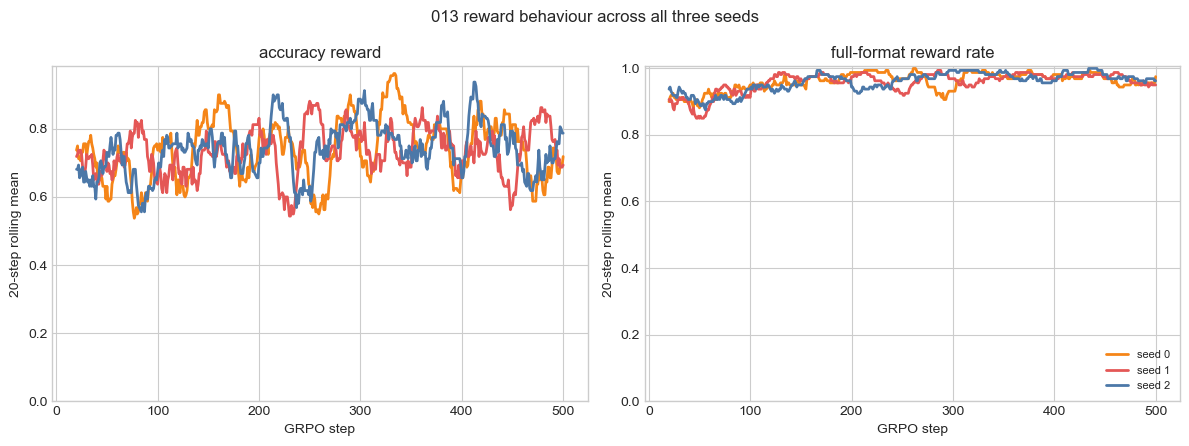

In [3]:
# plot both reward channels across all 500 GRPO steps for all three seeds
window = 20
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for seed, data in RUNS.items():
    for ax, key, title, divisor in [
        (axes[0], 'rewards/accuracy_reward/mean', 'accuracy reward', 1.0),
        (axes[1], 'rewards/format_reward/mean', 'full-format reward rate', 0.2),
    ]:
        x, values = series(data['g'], key)
        ax.plot(
            x[window - 1:], smooth(values / divisor, window),
            color=SEED_COLORS[seed], lw=2, label=f'seed {seed}',
        )
        ax.set_title(title)
        ax.set_xlabel('GRPO step')
        ax.set_ylabel('20-step rolling mean')
        ax.set_ylim(bottom=0)
axes[1].legend(fontsize=8, loc='lower right')
fig.suptitle('013 reward behaviour across all three seeds')
fig.tight_layout()
save(fig, 'fig01_training_rewards')
plt.show()


saved fig02_optimisation_health


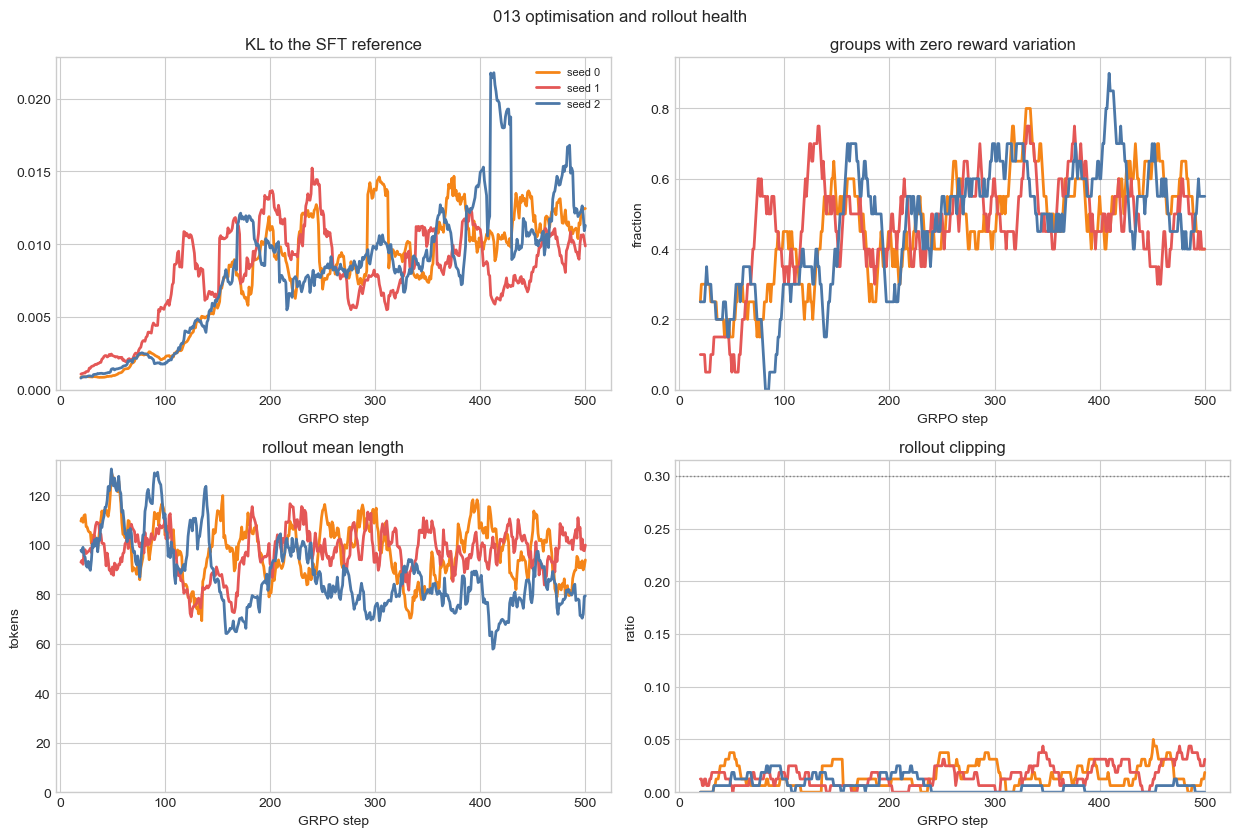

In [4]:
# compare policy movement and rollout health across all three seeds
panels = [
    ('kl', 'KL to the SFT reference', None),
    ('frac_reward_zero_std', 'groups with zero reward variation', 'fraction'),
    ('completions/mean_length', 'rollout mean length', 'tokens'),
    ('completions/clipped_ratio', 'rollout clipping', 'ratio'),
]
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.5))
for ax, (key, title, ylabel) in zip(axes.flat, panels):
    for seed, data in RUNS.items():
        x, values = series(data['g'], key)
        ax.plot(
            x[window - 1:], smooth(values, window),
            color=SEED_COLORS[seed], lw=2, label=f'seed {seed}',
        )
    if key == 'completions/clipped_ratio':
        ax.axhline(0.3, color='grey', ls=':', lw=1, label='A1 threshold')
    ax.set_title(title)
    ax.set_xlabel('GRPO step')
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.set_ylim(bottom=0)
axes[0, 0].legend(fontsize=8)
fig.suptitle('013 optimisation and rollout health')
fig.tight_layout()
save(fig, 'fig02_optimisation_health')
plt.show()


saved fig03_sft_loss


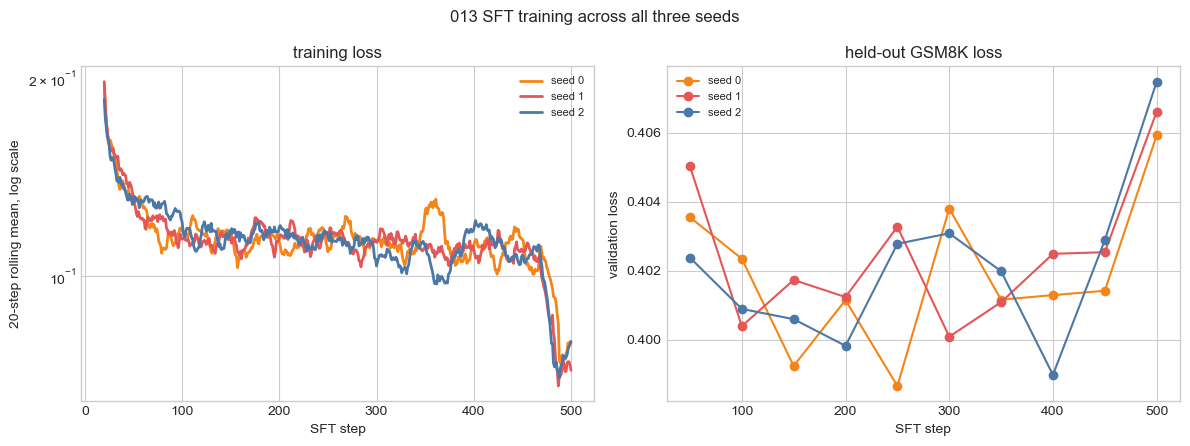

In [5]:
# compare SFT training and validation loss before the GRPO stage
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for seed, data in RUNS.items():
    x, values = series(data['s'], 'loss')
    axes[0].plot(
        x[window - 1:], smooth(values, window),
        color=SEED_COLORS[seed], lw=2, label=f'seed {seed}',
    )
    x, values = series(data['s'], 'eval_loss')
    axes[1].plot(x, values, 'o-', color=SEED_COLORS[seed], lw=1.5, label=f'seed {seed}')
axes[0].set_yscale('log')
axes[0].set_title('training loss')
axes[0].set_ylabel('20-step rolling mean, log scale')
axes[1].set_title('held-out GSM8K loss')
axes[1].set_ylabel('validation loss')
for ax in axes:
    ax.set_xlabel('SFT step')
    ax.legend(fontsize=8)
fig.suptitle('013 SFT training across all three seeds')
fig.tight_layout()
save(fig, 'fig03_sft_loss')
plt.show()


## 2. Three-seed endpoints and paired effects

Seed ranges are descriptive because three seeds are not enough for a formal
variance claim. Paired item-level changes are calculated separately for each
artifact. Holm adjustment is applied across the three seeds within each
difficulty group.


accuracy
seed stage group            
0    base  easy     0.869170
           medium   0.735632
           hard     0.595960
           overall  0.768577
     sft   easy     0.881684
           medium   0.756979
           hard     0.588384
           overall  0.779724
     grpo  easy     0.893060
           medium   0.776683
           hard     0.638889
           overall  0.802017
1    base  easy     0.869170
           medium   0.735632
           hard     0.595960
           overall  0.768577
     sft   easy     0.878271
           medium   0.753695
           hard     0.595960
           overall  0.778662
     grpo  easy     0.891923
           medium   0.776683
           hard     0.656566
           overall  0.805202
2    base  easy     0.869170
           medium   0.735632
           hard     0.595960
           overall  0.768577
     sft   easy     0.888510
           medium   0.778325
           hard     0.636364
           overall  0.799894
     grpo  easy     0.886234
           medium   0.798030
           hard     0.643939
           overall  0.806794

saved fig04_three_seed_endpoints


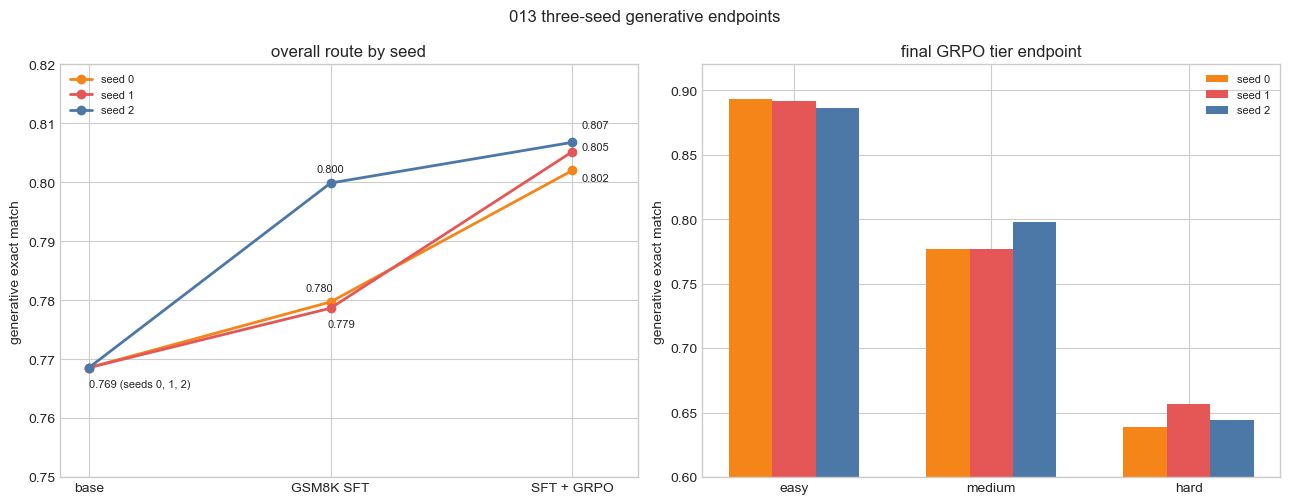

In [6]:
# plot the base to SFT to GRPO route and the tier endpoints for every seed
endpoint_rows = []
for seed, data in RUNS.items():
    for stage in ('base', 'sft', 'grpo'):
        for group in GROUPS:
            endpoint_rows.append({
                'seed': seed,
                'stage': stage,
                'group': group,
                'accuracy': group_accuracy(data['preds'][stage], group),
            })
endpoint_tbl = pd.DataFrame(endpoint_rows)
display(endpoint_tbl.set_index(['seed', 'stage', 'group']).round(6))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.1))
stage_x = np.arange(3)
for seed in RUNS:
    values = [
        endpoint_tbl.query('seed == @seed and stage == @stage and group == "overall"')['accuracy'].iloc[0]
        for stage in ('base', 'sft', 'grpo')
    ]
    axes[0].plot(stage_x, values, 'o-', color=SEED_COLORS[seed], lw=2, label=f'seed {seed}')
    sft_offset = {0: (-8, 8), 1: (8, -14), 2: (0, 8)}[seed]
    grpo_offset = {0: (7, -8), 1: (7, 1), 2: (7, 10)}[seed]
    for position, offset in [(1, sft_offset), (2, grpo_offset)]:
        axes[0].annotate(
            f'{values[position]:.3f}', (position, values[position]), xytext=offset,
            textcoords='offset points', ha='center' if position == 1 else 'left',
            fontsize=8,
        )
base_rows = endpoint_tbl.query('stage == "base" and group == "overall"')
for value, rows in base_rows.groupby('accuracy'):
    seed_list = ', '.join(rows['seed'].astype(str))
    axes[0].annotate(
        f'{value:.3f} (seeds {seed_list})', (0, value), xytext=(0, -14),
        textcoords='offset points', fontsize=8,
    )
axes[0].set_xlim(-0.12, 2.27)
axes[0].set_xticks(stage_x)
axes[0].set_xticklabels(['base', 'GSM8K SFT', 'SFT + GRPO'])
axes[0].set_ylim(0.75, 0.82)
axes[0].set_ylabel('generative exact match')
axes[0].set_title('overall route by seed')
axes[0].legend(fontsize=8, loc='upper left')

width = 0.22
for index, seed in enumerate(RUNS):
    values = [
        endpoint_tbl.query('seed == @seed and stage == "grpo" and group == @group')['accuracy'].iloc[0]
        for group in TIERS
    ]
    axes[1].bar(
        np.arange(len(TIERS)) + (index - 1) * width,
        values, width, color=SEED_COLORS[seed], label=f'seed {seed}',
    )
axes[1].set_xticks(np.arange(len(TIERS)))
axes[1].set_xticklabels(TIERS)
axes[1].set_ylim(0.60, 0.92)
axes[1].set_ylabel('generative exact match')
axes[1].set_title('final GRPO tier endpoint')
axes[1].legend(fontsize=8)
fig.suptitle('013 three-seed generative endpoints')
fig.tight_layout()
save(fig, 'fig04_three_seed_endpoints')
plt.show()


delta     ci_lo     ci_hi  sft_only_correct  \
group   seed                                                   
easy    0     0.011377 -0.003413  0.027304                19   
        1     0.013652 -0.001138  0.028441                16   
        2    -0.002275 -0.015927  0.011377                20   
hard    0     0.050505  0.002525  0.098485                38   
        1     0.060606  0.015152  0.106061                33   
        2     0.007576 -0.035354  0.053030                39   
medium  0     0.019704 -0.001642  0.042693                18   
        1     0.022989  0.001642  0.044335                16   
        2     0.019704 -0.001642  0.041051                16   
overall 0     0.022293  0.007962  0.036624                75   
        1     0.026539  0.012739  0.040340                65   
        2     0.006900 -0.006369  0.020170                75   

              grpo_only_correct  mcnemar_p  holm_p_across_seeds  
group   seed                                                     
easy    0                    29   0.193413             0.386825  
        1                    28   0.096142             0.288425  
        2                    18   0.871415             0.871415  
hard    0                    58   0.051911             0.103821  
        1                    57   0.014867             0.044600  
        2                    42   0.824313             0.824313  
medium  0                    30   0.111403             0.192284  
        1                    30   0.054076             0.162228  
        2                    28   0.096142             0.192284  
overall 0                   117   0.002987             0.005975  
        1                   115   0.000239             0.000717  
        2                    88   0.347293             0.347293

saved fig05_paired_grpo_effects


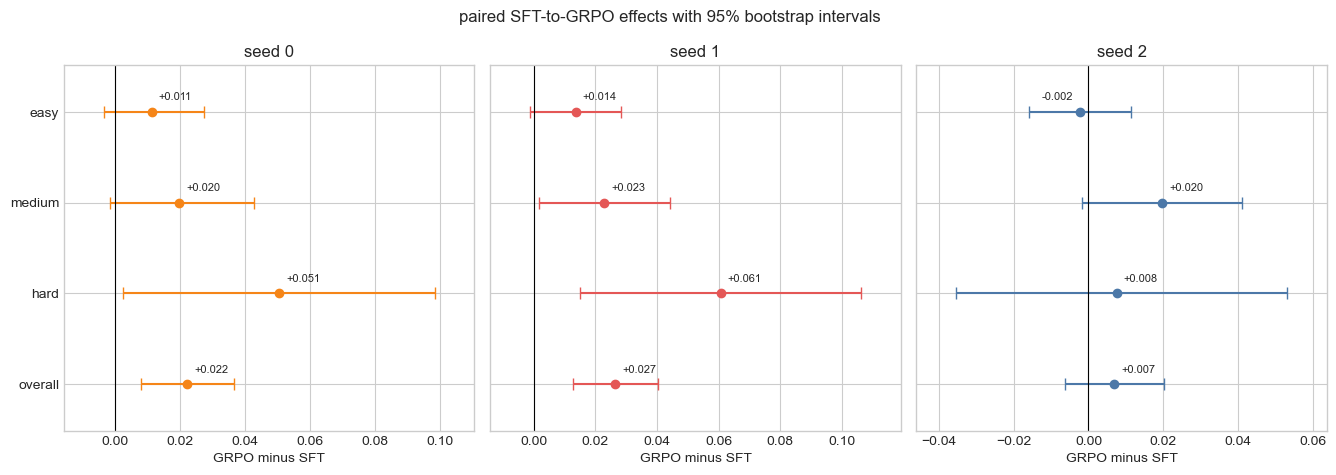

In [7]:
# calculate paired SFT-to-GRPO effects with Holm adjustment across seeds
paired_rows = []
for group_index, group in enumerate(GROUPS):
    group_rows_out = []
    for seed, data in RUNS.items():
        correct_sft, correct_grpo = paired_correct(data['preds']['sft'], data['preds']['grpo'], group)
        delta, lo, hi = paired_delta_ci(
            correct_sft, correct_grpo, seed=1300 + group_index * 10 + seed,
        )
        sft_only = sum(a and not b for a, b in zip(correct_sft, correct_grpo))
        grpo_only = sum((not a) and b for a, b in zip(correct_sft, correct_grpo))
        group_rows_out.append({
            'seed': seed,
            'group': group,
            'delta': delta,
            'ci_lo': lo,
            'ci_hi': hi,
            'sft_only_correct': sft_only,
            'grpo_only_correct': grpo_only,
            'mcnemar_p': mcnemar_exact(sft_only, grpo_only),
        })
    adjusted = holm([row['mcnemar_p'] for row in group_rows_out])
    for row, value in zip(group_rows_out, adjusted):
        row['holm_p_across_seeds'] = value
    paired_rows.extend(group_rows_out)

paired_tbl = pd.DataFrame(paired_rows).set_index(['group', 'seed']).sort_index()
display(paired_tbl.round(6))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.8), sharey=True)
for ax, seed in zip(axes, RUNS):
    table = paired_tbl.xs(seed, level='seed').loc[GROUPS]
    y = np.arange(len(GROUPS))
    values = table['delta'].to_numpy()
    errors = [values - table['ci_lo'].to_numpy(), table['ci_hi'].to_numpy() - values]
    ax.errorbar(values, y, xerr=errors, fmt='o', capsize=4, color=SEED_COLORS[seed])
    ax.axvline(0, color='black', lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels(GROUPS)
    ax.invert_yaxis()
    ax.set_xlabel('GRPO minus SFT')
    ax.set_title(f'seed {seed}')
    ax.margins(x=0.12, y=0.17)
    for position, value in zip(y, values):
        ax.annotate(f'{value:+.3f}', (value, position), xytext=(5 if value >= 0 else -5, 7),
                    textcoords='offset points', ha='left' if value >= 0 else 'right',
                    va='bottom', fontsize=8)
fig.suptitle('paired SFT-to-GRPO effects with 95% bootstrap intervals')
fig.tight_layout()
save(fig, 'fig05_paired_grpo_effects')
plt.show()


mean     min     max  range points
group   stage                                      
easy    sft    0.8828  0.8783  0.8885        1.0239
        grpo   0.8904  0.8862  0.8931        0.6826
medium  sft    0.7630  0.7537  0.7783        2.4631
        grpo   0.7838  0.7767  0.7980        2.1346
hard    sft    0.6069  0.5884  0.6364        4.7980
        grpo   0.6465  0.6389  0.6566        1.7677
overall sft    0.7861  0.7787  0.7999        2.1231
        grpo   0.8047  0.8020  0.8068        0.4777

saved fig06_seed_spread


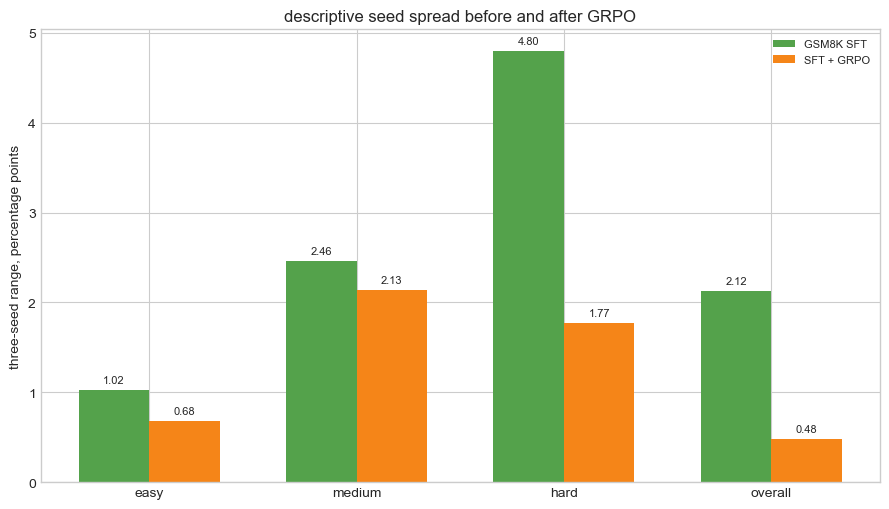

In [8]:
# compare the descriptive seed spread before and after GRPO
spread_rows = []
for group in GROUPS:
    for stage in ('sft', 'grpo'):
        values = [
            endpoint_tbl.query('seed == @seed and stage == @stage and group == @group')['accuracy'].iloc[0]
            for seed in RUNS
        ]
        spread_rows.append({
            'group': group,
            'stage': stage,
            'mean': np.mean(values),
            'min': min(values),
            'max': max(values),
            'range points': 100 * (max(values) - min(values)),
        })
spread_tbl = pd.DataFrame(spread_rows).set_index(['group', 'stage'])
display(spread_tbl.round(4))

fig, ax = plt.subplots(figsize=(9, 5.2))
x = np.arange(len(GROUPS))
width = 0.34
for offset, stage in [(-width / 2, 'sft'), (width / 2, 'grpo')]:
    values = [spread_tbl.loc[(group, stage), 'range points'] for group in GROUPS]
    bars = ax.bar(
        x + offset, values, width,
        color=STAGE_COLORS[stage], label='GSM8K SFT' if stage == 'sft' else 'SFT + GRPO',
    )
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.08, f'{value:.2f}', ha='center', fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(GROUPS)
ax.set_ylabel('three-seed range, percentage points')
ax.set_title('descriptive seed spread before and after GRPO')
ax.legend(fontsize=8)
fig.tight_layout()
save(fig, 'fig06_seed_spread')
plt.show()


## 3. Generative accuracy, probe and output behaviour

The probe is a diagnostic reference, not a proven ceiling. Generative-to-probe
margins are reported beside the direct SFT-to-GRPO changes so that the two
quantities are not treated as the same claim.


generative     probe  generative minus probe
seed stage group                                                
0    sft   easy       0.881684  0.899886               -0.018203
           medium     0.756979  0.807882               -0.050903
           hard       0.588384  0.568182                0.020202
           overall    0.779724  0.800425               -0.020701
     grpo  easy       0.893060  0.902162               -0.009101
           medium     0.776683  0.807882               -0.031199
           hard       0.638889  0.560606                0.078283
           overall    0.802017  0.799894                0.002123
1    sft   easy       0.878271  0.901024               -0.022753
           medium     0.753695  0.811166               -0.057471
           hard       0.595960  0.565657                0.030303
           overall    0.778662  0.801486               -0.022824
     grpo  easy       0.891923  0.898749               -0.006826
           medium     0.776683  0.809524               -0.032841
           hard       0.656566  0.565657                0.090909
           overall    0.805202  0.799894                0.005308
2    sft   easy       0.888510  0.898749               -0.010239
           medium     0.778325  0.811166               -0.032841
           hard       0.636364  0.555556                0.080808
           overall    0.799894  0.798301                0.001592
     grpo  easy       0.886234  0.897611               -0.011377
           medium     0.798030  0.806240               -0.008210
           hard       0.643939  0.553030                0.090909
           overall    0.806794  0.795648                0.011146

saved fig07_generation_and_probe


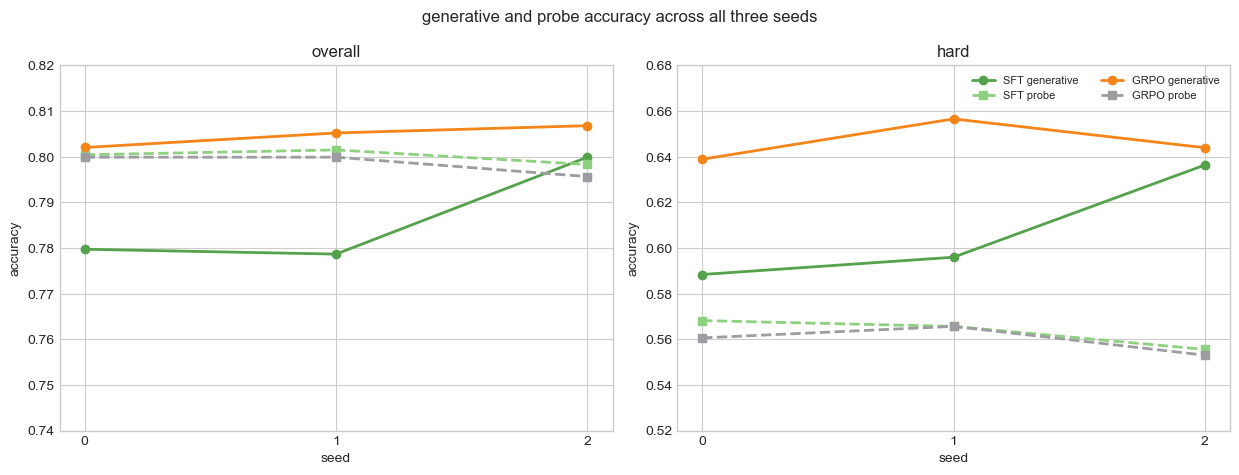

In [9]:
# compare generative and letter-probe accuracy at SFT and GRPO
probe_rows = []
for seed, data in RUNS.items():
    for stage in ('sft', 'grpo'):
        for group in GROUPS:
            gen = group_accuracy(data['preds'][stage], group)
            probe = group_accuracy(data['lp_preds'][stage], group)
            probe_rows.append({
                'seed': seed,
                'stage': stage,
                'group': group,
                'generative': gen,
                'probe': probe,
                'generative minus probe': gen - probe,
            })
probe_tbl = pd.DataFrame(probe_rows).set_index(['seed', 'stage', 'group'])
display(probe_tbl.round(6))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), sharex=True)
metric_specs = [
    ('sft', 'generative', '#54A24B', 'o-', 'SFT generative'),
    ('sft', 'probe', '#8CD17D', 's--', 'SFT probe'),
    ('grpo', 'generative', '#F58518', 'o-', 'GRPO generative'),
    ('grpo', 'probe', '#9D9DA1', 's--', 'GRPO probe'),
]
for ax, group in zip(axes, ('overall', 'hard')):
    for stage, metric, color, style, label in metric_specs:
        values = [probe_tbl.loc[(seed, stage, group), metric] for seed in RUNS]
        ax.plot(list(RUNS), values, style, color=color, lw=2, label=label)
    ax.set_xticks(list(RUNS))
    ax.set_xlabel('seed')
    ax.set_ylabel('accuracy')
    ax.set_title(group)
axes[0].set_ylim(0.74, 0.82)
axes[1].set_ylim(0.52, 0.68)
axes[1].legend(fontsize=8, ncol=2)
fig.suptitle('generative and probe accuracy across all three seeds')
fig.tight_layout()
save(fig, 'fig07_generation_and_probe')
plt.show()


format compliance  extraction failure  mean response length
seed stage                                                             
0    sft               0.9236              0.0223               87.2808
     grpo              0.9841              0.0117               66.4512
1    sft               0.9034              0.0244               89.4745
     grpo              0.9889              0.0090               66.9135
2    sft               0.9315              0.0223               81.8344
     grpo              0.9846              0.0106               65.4246

saved fig08_output_diagnostics


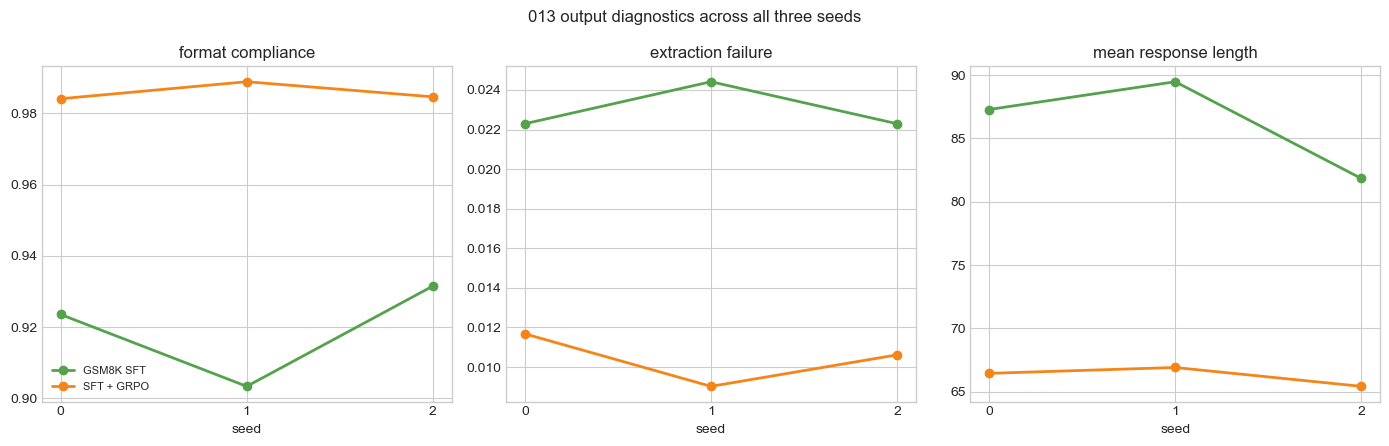

In [10]:
# compare format, extraction failure and response length for every seed
diagnostic_rows = []
for seed, data in RUNS.items():
    for stage in ('sft', 'grpo'):
        ev = data['eval'][stage]
        diagnostic_rows.append({
            'seed': seed,
            'stage': stage,
            'format compliance': ev['format_compliance'],
            'extraction failure': ev['extraction_failure_rate'],
            'mean response length': ev['mean_len'],
        })
diagnostics_tbl = pd.DataFrame(diagnostic_rows).set_index(['seed', 'stage'])
display(diagnostics_tbl.round(4))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, metric in zip(axes, ['format compliance', 'extraction failure', 'mean response length']):
    for stage in ('sft', 'grpo'):
        values = [diagnostics_tbl.loc[(seed, stage), metric] for seed in RUNS]
        ax.plot(
            list(RUNS), values, 'o-', color=STAGE_COLORS[stage], lw=2,
            label='GSM8K SFT' if stage == 'sft' else 'SFT + GRPO',
        )
    ax.set_xticks(list(RUNS))
    ax.set_xlabel('seed')
    ax.set_title(metric)
axes[0].legend(fontsize=8)
fig.suptitle('013 output diagnostics across all three seeds')
fig.tight_layout()
save(fig, 'fig08_output_diagnostics')
plt.show()


## 4. Subject-level consistency

Subject gains are calculated within each seed against its own SFT stage. The
mean column is descriptive and the three seed columns remain visible.


,tier,seed 0 gain,seed 1 gain,seed 2 gain,mean gain,range
subject,,,,,,
high_school_psychology,easy,0.0147,0.0183,0.0055,0.0128,0.0128
marketing,easy,0.0000,-0.0043,0.0000,-0.0014,0.0043
us_foreign_policy,easy,0.0200,0.0300,-0.0500,0.0000,0.0800
high_school_geography,medium,0.0505,0.0303,0.0253,0.0354,0.0253
philosophy,medium,0.0096,0.0289,0.0225,0.0204,0.0193
business_ethics,medium,-0.0100,-0.0100,0.0000,-0.0067,0.0100
high_school_mathematics,hard,0.0704,0.0667,0.0111,0.0494,0.0593
formal_logic,hard,0.0079,0.0476,0.0000,0.0185,0.0476


saved fig09_subject_gain_matrix


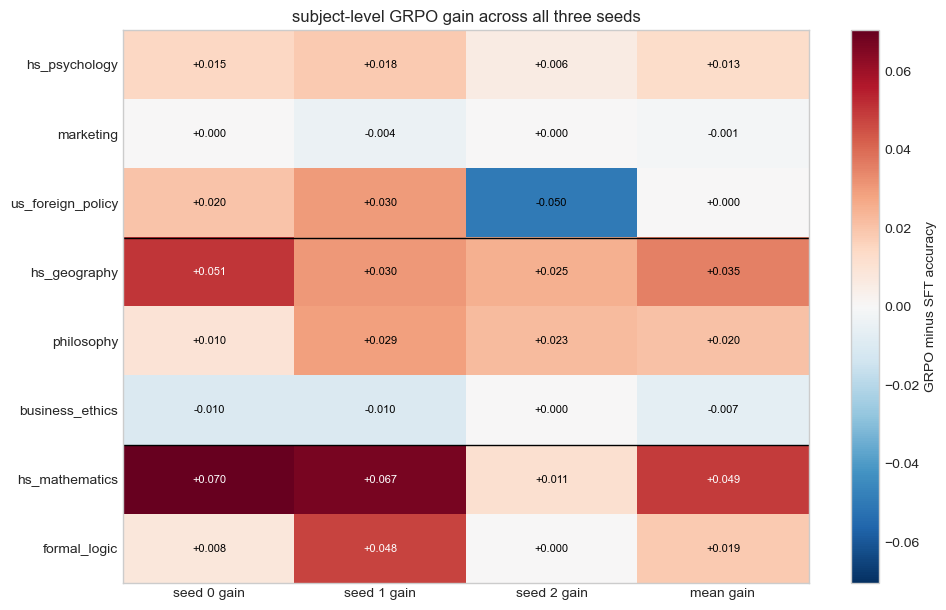

In [11]:
# show the subject-level SFT-to-GRPO change without hiding seed differences
subject_rows = []
for subject in SUBJECTS:
    row = {'subject': subject, 'tier': TIER_LOOKUP[subject]}
    values = []
    for seed, data in RUNS.items():
        gain = (
            data['eval']['grpo']['per_subject_acc'][subject]
            - data['eval']['sft']['per_subject_acc'][subject]
        )
        row[f'seed {seed} gain'] = gain
        values.append(gain)
    row['mean gain'] = np.mean(values)
    row['range'] = max(values) - min(values)
    subject_rows.append(row)
subject_tbl = pd.DataFrame(subject_rows).set_index('subject')
display(subject_tbl.round(4))

heat_cols = ['seed 0 gain', 'seed 1 gain', 'seed 2 gain', 'mean gain']
values = subject_tbl[heat_cols].to_numpy()
limit = max(abs(values.min()), abs(values.max()))
fig, ax = plt.subplots(figsize=(10, 6.2))
image = ax.imshow(
    values, cmap='RdBu_r',
    norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit),
    aspect='auto', interpolation='nearest',
)
ax.grid(False)
for row in range(values.shape[0]):
    for col in range(values.shape[1]):
        color = heatmap_text_color(image, values[row, col])
        ax.text(col, row, f'{values[row, col]:+.3f}', ha='center', va='center', fontsize=8, color=color)
ax.set_xticks(np.arange(len(heat_cols)))
ax.set_xticklabels(heat_cols)
ax.set_yticks(np.arange(len(subject_tbl)))
ax.set_yticklabels([subject.replace('high_school_', 'hs_') for subject in subject_tbl.index])
ax.axhline(2.5, color='black', lw=1)
ax.axhline(5.5, color='black', lw=1)
ax.set_title('subject-level GRPO gain across all three seeds')
fig.colorbar(image, ax=ax, label='GRPO minus SFT accuracy')
fig.tight_layout()
save(fig, 'fig09_subject_gain_matrix')
plt.show()


## 5. Cross-scale seed context

The A100 warm-route curve uses every completed reportable seed. Seed counts are
shown because the ranges are not equally precise across scales.


params_b  generative   probe                    GPU
scale seed                                                     
0.5B  0          0.5      0.4623  0.5679  NVIDIA A100-SXM4-40GB
      1          0.5      0.3153  0.5626  NVIDIA A100-SXM4-40GB
      2          0.5      0.5058  0.5600  NVIDIA A100-SXM4-40GB
1.5B  0          1.5      0.6741  0.7001  NVIDIA A100-SXM4-80GB
      1          1.5      0.6348  0.6980  NVIDIA A100-SXM4-80GB
3B    0          3.0      0.7160  0.7410  NVIDIA A100-SXM4-80GB
      1          3.0      0.7266  0.7447  NVIDIA A100-SXM4-80GB
7B    0          7.0      0.8020  0.7999  NVIDIA A100-SXM4-80GB
      1          7.0      0.8052  0.7999  NVIDIA A100-SXM4-80GB
      2          7.0      0.8068  0.7956  NVIDIA A100-SXM4-80GB

,params_b,n_seeds,generative mean,generative min,generative max,seed range points,probe mean
scale,,,,,,,
0.5B,0.5,3,0.4278,0.3153,0.5058,19.0552,0.5635
1.5B,1.5,2,0.6545,0.6348,0.6741,3.9278,0.6990
3B,3.0,2,0.7213,0.7160,0.7266,1.0616,0.7428
7B,7.0,3,0.8047,0.8020,0.8068,0.4777,0.7985


saved fig10_cross_scale_seed_context


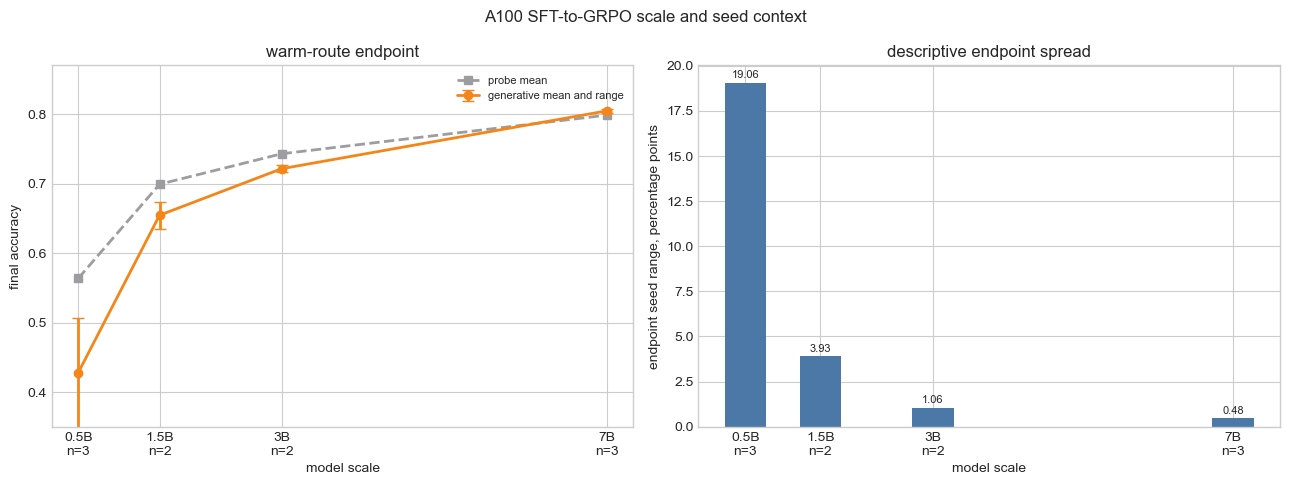

In [12]:
# update the A100 scale curve and endpoint ranges with the third 7B seed
scale_seed_rows = []
scale_rows = []
for scale, spec in SCALE_SPECS.items():
    gen_values = []
    probe_values = []
    for seed in spec['seeds']:
        tag = f"{spec['experiment']}_COLAB_FULL_{spec['code']}_sft_grpo_seed{seed}"
        run_dir = RES / tag
        gen_rows = jsonl(run_dir / 'grpo_preds.jsonl')
        probe_rows_scale = jsonl(run_dir / 'grpo_logprob_preds.jsonl')
        manifest = jload(run_dir / 'manifest.json')
        assert 'A100' in manifest['gpu']['device']
        gen = accuracy(gen_rows)
        probe = accuracy(probe_rows_scale)
        gen_values.append(gen)
        probe_values.append(probe)
        scale_seed_rows.append({
            'scale': scale,
            'params_b': spec['params'],
            'seed': seed,
            'generative': gen,
            'probe': probe,
            'GPU': manifest['gpu']['device'],
        })
    scale_rows.append({
        'scale': scale,
        'params_b': spec['params'],
        'n_seeds': len(gen_values),
        'generative mean': np.mean(gen_values),
        'generative min': min(gen_values),
        'generative max': max(gen_values),
        'seed range points': 100 * (max(gen_values) - min(gen_values)),
        'probe mean': np.mean(probe_values),
    })

scale_seed_tbl = pd.DataFrame(scale_seed_rows)
scale_tbl = pd.DataFrame(scale_rows).sort_values('params_b').set_index('scale')
display(scale_seed_tbl.set_index(['scale', 'seed']).round(4))
display(scale_tbl.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.9))
x = scale_tbl['params_b'].to_numpy()
mean = scale_tbl['generative mean'].to_numpy()
low = mean - scale_tbl['generative min'].to_numpy()
high = scale_tbl['generative max'].to_numpy() - mean
axes[0].errorbar(
    x, mean, yerr=[low, high], marker='o', lw=2, capsize=4,
    color=STAGE_COLORS['grpo'], label='generative mean and range',
)
axes[0].plot(x, scale_tbl['probe mean'], 's--', color='#9D9DA1', lw=2, label='probe mean')
axes[0].set_ylabel('final accuracy')
axes[0].set_ylim(0.35, 0.87)
axes[0].set_title('warm-route endpoint')
axes[0].legend(fontsize=8)

bars = axes[1].bar(x, scale_tbl['seed range points'], color='#4C78A8', width=0.55)
for bar, value in zip(bars, scale_tbl['seed range points']):
    axes[1].text(bar.get_x() + bar.get_width() / 2, value + 0.25, f'{value:.2f}', ha='center', fontsize=8)
axes[1].set_ylabel('endpoint seed range, percentage points')
axes[1].set_title('descriptive endpoint spread')
for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels([
        f'{scale}\nn={int(scale_tbl.loc[scale, "n_seeds"])}'
        for scale in scale_tbl.index
    ])
    ax.set_xlabel('model scale')
fig.suptitle('A100 SFT-to-GRPO scale and seed context')
fig.tight_layout()
save(fig, 'fig10_cross_scale_seed_context')
plt.show()


## 6. Compute and exact tables


,SFT train,SFT eval,SFT probe,GRPO train,GRPO eval,GRPO probe,peak VRAM GB,total recorded hours
seed,,,,,,,,
0,0.2635,0.7479,0.0119,2.9679,0.5210,0.0134,71.317,4.5256
1,0.2706,0.7389,0.0106,2.8640,0.5238,0.0123,71.317,4.4202
2,0.2747,0.6968,0.0119,2.4326,0.4969,0.0134,70.986,3.9262


saved fig11_compute


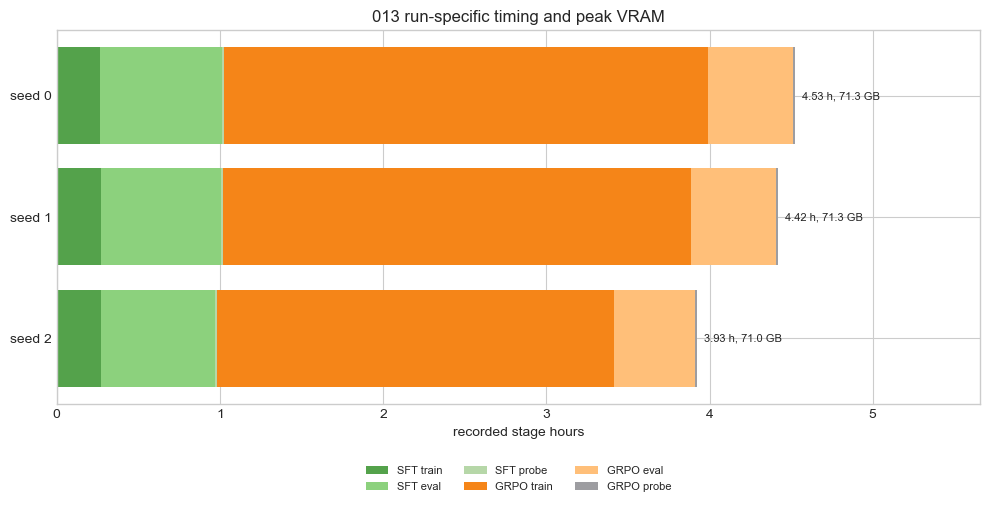

closed seed-2 compute-unit sessions


,ts_start,notebook,colab_cu_before,unit_rate,ts_end,colab_cu_after,colab_cu_used,closed_on_resume
session_id,,,,,,,,
20260730_145539,2026-07-30 14:55,013_colab_7b_seed2,346.77,6.77,2026-07-30 14:59,346.77,0.0,True
20260730_145903,2026-07-30 14:59,013_colab_7b_seed2,346.77,6.77,2026-07-30 15:02,346.77,0.0,True


the main seed-2 compute-unit session is still open


,ts_start,notebook,colab_cu_before,unit_rate
session_id,,,,
20260730_150158,2026-07-30 15:02,013_colab_7b_seed2,346.77,6.77


In [13]:
# compare run-specific stage time without counting the shared base evaluation
compute_rows = []
for seed, data in RUNS.items():
    timings = data['man']['timings_sec']
    compute_rows.append({
        'seed': seed,
        'SFT train': timings.get('sft_train', 0) / 3600,
        'SFT eval': timings.get('sft_eval', 0) / 3600,
        'SFT probe': timings.get('sft_logprob_eval', 0) / 3600,
        'GRPO train': timings.get('grpo_train', 0) / 3600,
        'GRPO eval': timings.get('grpo_eval', 0) / 3600,
        'GRPO probe': timings.get('grpo_logprob_eval', 0) / 3600,
        'peak VRAM GB': data['man']['gpu']['peak_vram_gb'],
    })
compute_tbl = pd.DataFrame(compute_rows).set_index('seed')
parts = ['SFT train', 'SFT eval', 'SFT probe', 'GRPO train', 'GRPO eval', 'GRPO probe']
compute_tbl['total recorded hours'] = compute_tbl[parts].sum(axis=1)
display(compute_tbl.round(4))

fig, ax = plt.subplots(figsize=(10, 5.2))
part_colors = ['#54A24B', '#8CD17D', '#B6D7A8', '#F58518', '#FFBF79', '#9D9DA1']
left = np.zeros(len(compute_tbl))
for part, color in zip(parts, part_colors):
    values = compute_tbl[part].to_numpy()
    ax.barh(np.arange(len(compute_tbl)), values, left=left, color=color, label=part)
    left += values
for position, (total, vram) in enumerate(zip(
    compute_tbl['total recorded hours'], compute_tbl['peak VRAM GB'],
)):
    ax.text(total + 0.04, position, f'{total:.2f} h, {vram:.1f} GB', va='center', fontsize=8)
ax.set_yticks(np.arange(len(compute_tbl)))
ax.set_yticklabels([f'seed {seed}' for seed in compute_tbl.index])
ax.invert_yaxis()
ax.set_xlabel('recorded stage hours')
ax.set_title('013 run-specific timing and peak VRAM')
ax.margins(x=0.25)
ax.legend(fontsize=8, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.14))
fig.tight_layout()
save(fig, 'fig11_compute')
plt.show()

unit_rows = raw_jsonl(RES / 'colab_units.jsonl')
seed2_units = [row for row in unit_rows if row.get('notebook') == '013_colab_7b_seed2']
open_unit_files = sorted((RES / 'open_cu_sessions').glob('*.json'))
open_seed2_units = [
    jload(path) for path in open_unit_files
    if jload(path).get('notebook') == '013_colab_7b_seed2'
]
if seed2_units:
    print('closed seed-2 compute-unit sessions')
    display(pd.DataFrame(seed2_units).set_index('session_id'))
if open_seed2_units:
    print('the main seed-2 compute-unit session is still open')
    display(pd.DataFrame(open_seed2_units).set_index('session_id'))
elif not seed2_units:
    print('no seed-2 compute-unit record found in the pulled results')


In [14]:
# keep the exact values used by the plots in compact tables
display(health_tbl.round(5))
display(endpoint_tbl.set_index(['seed', 'stage', 'group']).round(6))
display(paired_tbl.round(6))
display(spread_tbl.round(5))
display(probe_tbl.round(6))
display(diagnostics_tbl.round(5))
display(subject_tbl.round(5))
display(scale_tbl.round(5))
display(compute_tbl.round(4))


,SFT steps,GRPO steps,eval items,first-50 clipped ratio,last-50 KL,non-finite values,peak VRAM GB,recorded hours
seed,,,,,,,,
0,500,500,1884,0.0150,0.01217,0,71.317,5.03177
1,500,500,1884,0.0125,0.00986,0,71.317,4.42016
2,500,500,1884,0.0075,0.01237,0,70.986,3.92621


accuracy
seed stage group            
0    base  easy     0.869170
           medium   0.735632
           hard     0.595960
           overall  0.768577
     sft   easy     0.881684
           medium   0.756979
           hard     0.588384
           overall  0.779724
     grpo  easy     0.893060
           medium   0.776683
           hard     0.638889
           overall  0.802017
1    base  easy     0.869170
           medium   0.735632
           hard     0.595960
           overall  0.768577
     sft   easy     0.878271
           medium   0.753695
           hard     0.595960
           overall  0.778662
     grpo  easy     0.891923
           medium   0.776683
           hard     0.656566
           overall  0.805202
2    base  easy     0.869170
           medium   0.735632
           hard     0.595960
           overall  0.768577
     sft   easy     0.888510
           medium   0.778325
           hard     0.636364
           overall  0.799894
     grpo  easy     0.886234
           medium   0.798030
           hard     0.643939
           overall  0.806794

delta     ci_lo     ci_hi  sft_only_correct  \
group   seed                                                   
easy    0     0.011377 -0.003413  0.027304                19   
        1     0.013652 -0.001138  0.028441                16   
        2    -0.002275 -0.015927  0.011377                20   
hard    0     0.050505  0.002525  0.098485                38   
        1     0.060606  0.015152  0.106061                33   
        2     0.007576 -0.035354  0.053030                39   
medium  0     0.019704 -0.001642  0.042693                18   
        1     0.022989  0.001642  0.044335                16   
        2     0.019704 -0.001642  0.041051                16   
overall 0     0.022293  0.007962  0.036624                75   
        1     0.026539  0.012739  0.040340                65   
        2     0.006900 -0.006369  0.020170                75   

              grpo_only_correct  mcnemar_p  holm_p_across_seeds  
group   seed                                                     
easy    0                    29   0.193413             0.386825  
        1                    28   0.096142             0.288425  
        2                    18   0.871415             0.871415  
hard    0                    58   0.051911             0.103821  
        1                    57   0.014867             0.044600  
        2                    42   0.824313             0.824313  
medium  0                    30   0.111403             0.192284  
        1                    30   0.054076             0.162228  
        2                    28   0.096142             0.192284  
overall 0                   117   0.002987             0.005975  
        1                   115   0.000239             0.000717  
        2                    88   0.347293             0.347293

mean      min      max  range points
group   stage                                         
easy    sft    0.88282  0.87827  0.88851       1.02389
        grpo   0.89041  0.88623  0.89306       0.68259
medium  sft    0.76300  0.75369  0.77833       2.46305
        grpo   0.78380  0.77668  0.79803       2.13465
hard    sft    0.60690  0.58838  0.63636       4.79798
        grpo   0.64646  0.63889  0.65657       1.76768
overall sft    0.78609  0.77866  0.79989       2.12314
        grpo   0.80467  0.80202  0.80679       0.47771

generative     probe  generative minus probe
seed stage group                                                
0    sft   easy       0.881684  0.899886               -0.018203
           medium     0.756979  0.807882               -0.050903
           hard       0.588384  0.568182                0.020202
           overall    0.779724  0.800425               -0.020701
     grpo  easy       0.893060  0.902162               -0.009101
           medium     0.776683  0.807882               -0.031199
           hard       0.638889  0.560606                0.078283
           overall    0.802017  0.799894                0.002123
1    sft   easy       0.878271  0.901024               -0.022753
           medium     0.753695  0.811166               -0.057471
           hard       0.595960  0.565657                0.030303
           overall    0.778662  0.801486               -0.022824
     grpo  easy       0.891923  0.898749               -0.006826
           medium     0.776683  0.809524               -0.032841
           hard       0.656566  0.565657                0.090909
           overall    0.805202  0.799894                0.005308
2    sft   easy       0.888510  0.898749               -0.010239
           medium     0.778325  0.811166               -0.032841
           hard       0.636364  0.555556                0.080808
           overall    0.799894  0.798301                0.001592
     grpo  easy       0.886234  0.897611               -0.011377
           medium     0.798030  0.806240               -0.008210
           hard       0.643939  0.553030                0.090909
           overall    0.806794  0.795648                0.011146

format compliance  extraction failure  mean response length
seed stage                                                             
0    sft              0.92357             0.02229              87.28079
     grpo             0.98408             0.01168              66.45117
1    sft              0.90340             0.02442              89.47452
     grpo             0.98885             0.00902              66.91348
2    sft              0.93153             0.02229              81.83439
     grpo             0.98461             0.01062              65.42463

,tier,seed 0 gain,seed 1 gain,seed 2 gain,mean gain,range
subject,,,,,,
high_school_psychology,easy,0.01468,0.01835,0.00550,0.01284,0.01284
marketing,easy,0.00000,-0.00427,0.00000,-0.00142,0.00427
us_foreign_policy,easy,0.02000,0.03000,-0.05000,0.00000,0.08000
high_school_geography,medium,0.05051,0.03030,0.02525,0.03535,0.02525
philosophy,medium,0.00965,0.02894,0.02251,0.02036,0.01929
business_ethics,medium,-0.01000,-0.01000,0.00000,-0.00667,0.01000
high_school_mathematics,hard,0.07037,0.06667,0.01111,0.04938,0.05926
formal_logic,hard,0.00794,0.04762,0.00000,0.01852,0.04762


,params_b,n_seeds,generative mean,generative min,generative max,seed range points,probe mean
scale,,,,,,,
0.5B,0.5,3,0.42781,0.31529,0.50584,19.05520,0.56352
1.5B,1.5,2,0.65446,0.63482,0.67410,3.92781,0.69904
3B,3.0,2,0.72134,0.71603,0.72665,1.06157,0.74283
7B,7.0,3,0.80467,0.80202,0.80679,0.47771,0.79848


,SFT train,SFT eval,SFT probe,GRPO train,GRPO eval,GRPO probe,peak VRAM GB,total recorded hours
seed,,,,,,,,
0,0.2635,0.7479,0.0119,2.9679,0.5210,0.0134,71.317,4.5256
1,0.2706,0.7389,0.0106,2.8640,0.5238,0.0123,71.317,4.4202
2,0.2747,0.6968,0.0119,2.4326,0.4969,0.0134,70.986,3.9262


## Cross-referenced conclusion

All three 013 SFT-to-GRPO runs finished normally on an A100 80GB in BF16. Each
run reached 500 SFT and 500 GRPO steps, every evaluation contains 1,884 items,
the OOM ladder stayed off and no interruption or non-finite value was found.
The new seed 2 run took 3.94 recorded hours and peaked at 71.0 GB.

Final GRPO accuracy is 80.20%, 80.52% and 80.68%. The three-seed mean is 80.47%
and the range is 0.48 points, so the stable 7B endpoint finding still holds.
The SFT endpoints have a wider 2.12-point range, while the GRPO endpoints have
a 0.48-point range. This contraction is descriptive because there are only
three seeds.

The incremental GRPO effect is not the same in every seed. GRPO improves over
SFT by 2.23, 2.65 and 0.69 points. The first two overall changes remain
significant after Holm adjustment across three seeds, but seed 2 does not. A
single common three-seed claim of material improvement is therefore not
supported, even though the final endpoints are very close.

The hard GRPO endpoints are 63.89%, 65.66% and 64.39%. All three remain 7.83 to
9.09 points above their own hard-tier probes. However, seed 2 already reaches
63.64% at the SFT stage, so its hard-tier GRPO gain is only 0.76 points. This
strengthens the final hard-endpoint replication but weakens the interpretation
that the above-probe margin is produced by GRPO alone. 

Supervised controls and direct changes for each seed remain necessary for that claim.

Across the A100 warm-route experiments, the endpoint seed ranges are largest
at 0.5B and smallest at 7B. 
The added seed changes the 7B range from 0.32 to 0.48 points, 
which does not change scale level stability conclusion.
